# Parte 2 – Mapas del Perú

**Pregunta:** *¿El Estado declara emergencia donde más llueve?* (temporada 1 de enero – 31 de mayo de 2023).

Usamos nuestra `tabla_final.csv` del Assignment 2 (copiada como `datos/dataset.csv`) y las fronteras
departamentales de la sesión 7 (`departamentos_peru.geojson`, descargado con `fetch_data.py 07-mapas`).
Como en clase, el paso que importa no es dibujar: es **cruzar por ubigeo**.

In [1]:
import unicodedata

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

## 1. Cargar los datos y las fronteras

In [2]:
datos = pd.read_csv("datos/dataset.csv", dtype={"ubigeo": str})
print(datos.shape)
datos.head()

(25, 9)


,ubigeo,departamento,capital,latitud,longitud,lluvia_total_mm,dias_lluvia_fuerte,declaratorias,prorrogas
0,01,Amazonas,Chachapoyas,-6.23169,-77.86903,414.6,3,3,1
1,02,Áncash,Huaraz,-9.52614,-77.52869,1145.8,9,6,1
2,03,Apurímac,Abancay,-13.63426,-72.88380,726.2,3,1,0
3,04,Arequipa,Arequipa,-16.39899,-71.53747,362.0,1,4,0
4,05,Ayacucho,Ayacucho,-13.16380,-74.22345,498.4,2,5,1


In [3]:
departamentos = gpd.read_file("datos/departamentos_peru.geojson")
print(departamentos.shape, departamentos.crs)
departamentos.head()

(25, 2) EPSG:4326


,departamento,geometry
0,AMAZONAS,"POLYGON ((-78.03025 -6.7661, -78.04983 -6.6838..."
1,ANCASH,"POLYGON ((-77.69239 -10.3209, -77.75251 -10.32..."
2,APURIMAC,"POLYGON ((-73.51174 -14.53852, -73.52075 -14.5..."
3,AREQUIPA,"POLYGON ((-72.72968 -16.64631, -72.77421 -16.6..."
4,AYACUCHO,"POLYGON ((-74.50188 -15.16058, -74.51267 -15.1..."


El GeoJSON está en `EPSG:4326` (latitud y longitud), así que no hace falta `.to_crs()`.
Pero **no trae ubigeo**: solo el nombre en mayúsculas y sin tildes (`ANCASH`, `JUNIN`, `SAN MARTIN`).

<Axes: >

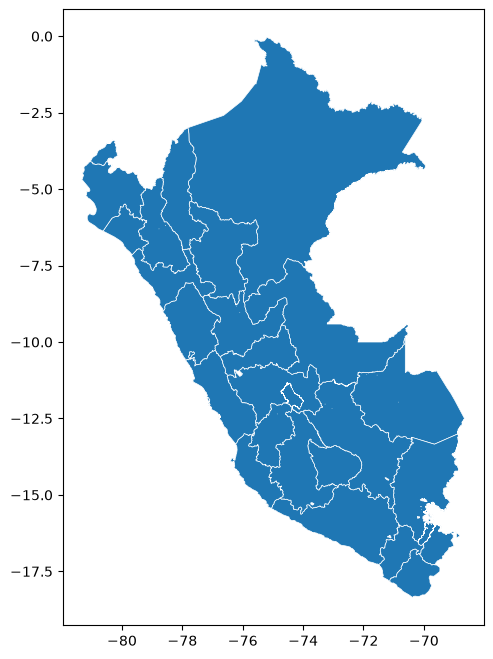

In [4]:
departamentos.plot(figsize=(6, 8), edgecolor="white", linewidth=0.5)

## 2. Agregar el ubigeo a las fronteras

Le pegamos el ubigeo usando una llave normalizada (sin tildes, minúsculas), la misma función
`normalizar` que usamos en el Assignment 2. Así `"ANCASH"` y `"Áncash"` quedan como `"ancash"`.

In [5]:
def normalizar(texto):
    texto = str(texto).strip().lower()
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return " ".join(texto.split())

llaves = datos[["ubigeo", "departamento"]].copy()
llaves["llave"] = llaves["departamento"].apply(normalizar)

departamentos["llave"] = departamentos["departamento"].apply(normalizar)
departamentos = departamentos.merge(llaves[["llave", "ubigeo"]], on="llave", how="left")

print("Fronteras sin ubigeo:", departamentos[departamentos["ubigeo"].isna()]["departamento"].tolist())
departamentos[["departamento", "ubigeo"]].head()

Fronteras sin ubigeo: []


,departamento,ubigeo
0,AMAZONAS,01
1,ANCASH,02
2,APURIMAC,03
3,AREQUIPA,04
4,AYACUCHO,05


## 3. Verificar antes de cruzar

Los tres chequeos de la sesión 7: el tipo de dato, un ejemplo y cuántos coinciden.
El ubigeo debe ser **texto de 2 dígitos** en ambos lados (`'01'`, no `1`).

In [6]:
print("Mapa  :", departamentos["ubigeo"].dtype, "| ejemplo:", repr(departamentos["ubigeo"].iloc[0]))
print("Tabla :", datos["ubigeo"].dtype, "| ejemplo:", repr(datos["ubigeo"].iloc[0]))
print("Coinciden:", len(set(departamentos["ubigeo"]) & set(datos["ubigeo"])), "de", len(datos))

Mapa  : object | ejemplo: '01'
Tabla : object | ejemplo: '01'
Coinciden: 25 de 25


### Qué pasa si leemos el ubigeo como número

Si olvidamos `dtype=str`, `"01"` se vuelve `1` y ya no coincide con el `"01"` del mapa.

In [7]:
datos_mal = pd.read_csv("datos/dataset.csv")
print("Tipo:", datos_mal["ubigeo"].dtype, "| ejemplo:", repr(datos_mal["ubigeo"].iloc[0]))
print("Coinciden leyendo como número:", len(set(departamentos["ubigeo"]) & set(datos_mal["ubigeo"])), "de", len(datos_mal))

Tipo: int64 | ejemplo: np.int64(1)
Coinciden leyendo como número: 0 de 25


## 4. El merge, con reporte de lo que no cruzó

Usamos `how="outer"` con `indicator=True` para ver de una vez si quedó algo solo en el mapa
o solo en la tabla. Si todo cruzó, la columna `_merge` dice `both` en las 25 filas.

In [8]:
mapa = departamentos[["ubigeo", "geometry"]].merge(
    datos, on="ubigeo", how="outer", indicator=True
)
print(mapa["_merge"].value_counts())

no_cruzaron = mapa[mapa["_merge"] != "both"]
print("\nNo cruzaron:", len(no_cruzaron))
no_cruzaron[["ubigeo", "departamento", "_merge"]]

_merge
both          25
left_only      0
right_only     0
Name: count, dtype: int64

No cruzaron: 0


,ubigeo,departamento,_merge


In [9]:
assert len(no_cruzaron) == 0, "Hay departamentos que no cruzaron"
mapa = gpd.GeoDataFrame(mapa.drop(columns="_merge"), geometry="geometry", crs=departamentos.crs)

print("Declaratorias en la tabla:", datos["declaratorias"].sum())
print("Declaratorias en el mapa :", mapa["declaratorias"].sum())
print("Lluvia total en la tabla :", round(datos["lluvia_total_mm"].sum(), 1))
print("Lluvia total en el mapa  :", round(mapa["lluvia_total_mm"].sum(), 1))

Declaratorias en la tabla: 73
Declaratorias en el mapa : 73
Lluvia total en la tabla : 16091.3
Lluvia total en el mapa  : 16091.3


Los totales coinciden: el cruce no perdió ni duplicó nada. Los 25 departamentos cruzaron por ubigeo.

## 5. Coropletas estáticas por cuantiles

Con `scheme="quantiles"` cada color agrupa la misma cantidad de departamentos, para que
Loreto (1,605 mm) no deje a todos los demás en blanco. Ponemos los dos mapas lado a lado
para comparar lluvia y declaratorias.

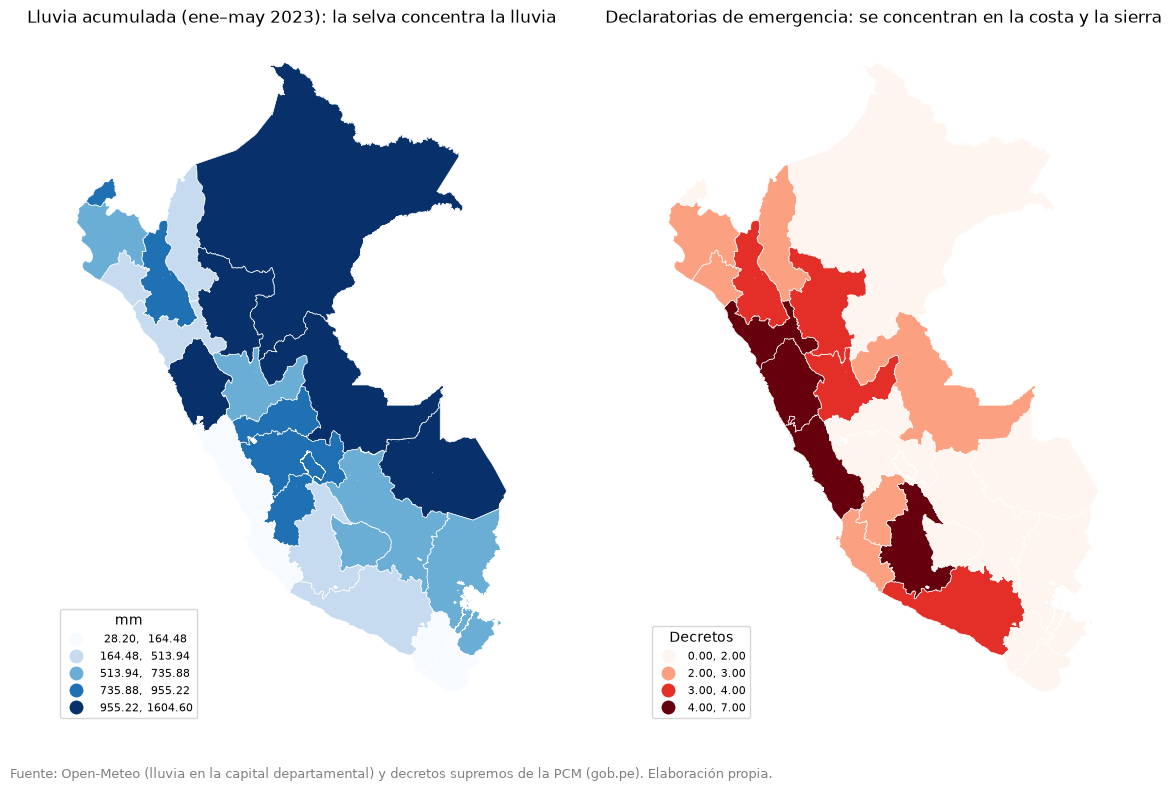

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 9))

mapa.plot(column="lluvia_total_mm", cmap="Blues", scheme="quantiles", k=5,
          legend=True, edgecolor="white", linewidth=0.5, ax=ejes[0],
          legend_kwds={"loc": "lower left", "fontsize": 8, "title": "mm"})
ejes[0].set_title("Lluvia acumulada (ene–may 2023): la selva concentra la lluvia")

mapa.plot(column="declaratorias", cmap="Reds", scheme="quantiles", k=4,
          legend=True, edgecolor="white", linewidth=0.5, ax=ejes[1],
          legend_kwds={"loc": "lower left", "fontsize": 8, "title": "Decretos"})
ejes[1].set_title("Declaratorias de emergencia: se concentran en la costa y la sierra")

for eje in ejes:
    eje.set_axis_off()

fig.text(0.1, 0.05, "Fuente: Open-Meteo (lluvia en la capital departamental) y decretos supremos de la PCM (gob.pe). Elaboración propia.",
         fontsize=9, color="gray")
plt.show()

### Un tercer mapa: declaratorias por cada 100 mm de lluvia

Divide los decretos entre la lluvia. Valores altos = mucha emergencia para la lluvia que cayó en la capital.

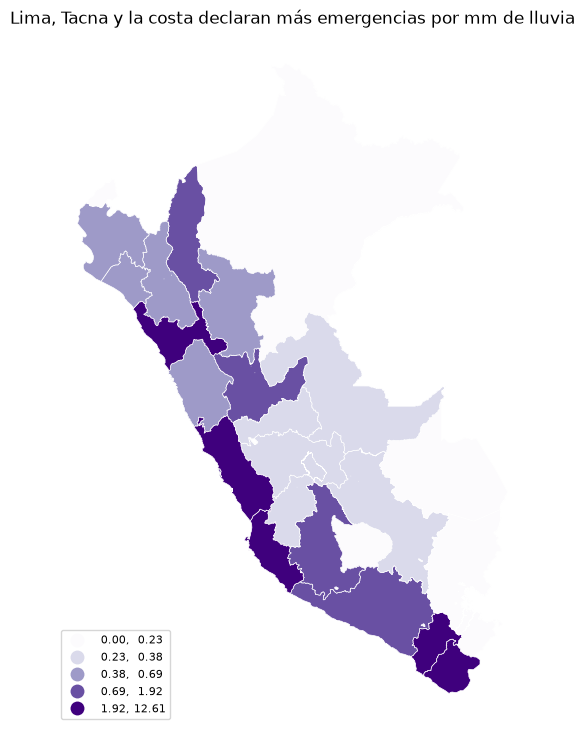

,departamento,lluvia_total_mm,declaratorias,decretos_por_100mm
14,Lima,55.5,7,12.61
22,Tacna,28.2,2,7.09
12,La Libertad,177.2,5,2.82
10,Ica,113.6,3,2.64
17,Moquegua,83.9,2,2.38


In [11]:
mapa["decretos_por_100mm"] = (mapa["declaratorias"] / mapa["lluvia_total_mm"] * 100).round(2)

ax = mapa.plot(column="decretos_por_100mm", cmap="Purples", scheme="quantiles", k=5,
               legend=True, edgecolor="white", linewidth=0.5, figsize=(7, 9),
               legend_kwds={"loc": "lower left", "fontsize": 8})
ax.set_title("Lima, Tacna y la costa declaran más emergencias por mm de lluvia")
ax.set_axis_off()
plt.show()

mapa.sort_values("decretos_por_100mm", ascending=False)[
    ["departamento", "lluvia_total_mm", "declaratorias", "decretos_por_100mm"]
].head(5)

## 6. Mapa interactivo con Folium

`Choropleth` pinta la lluvia y una capa `GeoJson` encima muestra el dato al pasar el mouse.
Además ponemos un círculo en cada capital, de tamaño proporcional a las declaratorias, para ver
las dos variables en un solo mapa.

> El notebook se guarda sin la salida de este mapa (pesa varios MB). Se genera al correr la celda.

In [ ]:
import folium

m = folium.Map(location=[-9.2, -75.0], zoom_start=5, tiles="OpenStreetMap")

folium.Choropleth(
    geo_data=mapa,
    data=mapa,
    columns=["ubigeo", "lluvia_total_mm"],
    key_on="feature.properties.ubigeo",
    fill_color="Blues",
    fill_opacity=0.7,
    line_opacity=0.3,
    legend_name="Lluvia acumulada ene–may 2023 (mm)",
).add_to(m)

folium.GeoJson(
    mapa,
    style_function=lambda x: {"fillOpacity": 0, "weight": 0},
    tooltip=folium.GeoJsonTooltip(
        fields=["departamento", "lluvia_total_mm", "dias_lluvia_fuerte", "declaratorias", "prorrogas"],
        aliases=["Departamento:", "Lluvia (mm):", "Días ≥ 20 mm:", "Declaratorias:", "Prórrogas:"],
    ),
).add_to(m)

for _, fila in mapa.iterrows():
    folium.CircleMarker(
        location=[fila["latitud"], fila["longitud"]],
        radius=3 + fila["declaratorias"] * 2,
        color="darkred",
        fill=True,
        fill_opacity=0.6,
        popup=f"{fila['capital']}: {fila['declaratorias']} declaratorias",
    ).add_to(m)

m.save("mapa_lluvias_emergencias.html")
m

## 7. ¿Qué patrón geográfico resalta?

- **La lluvia y las emergencias están en lugares distintos.** Los azules más oscuros están en la selva
  (Loreto, Ucayali, Madre de Dios, San Martín), pero los rojos más oscuros están en la costa y la sierra
  (Lima con 7 declaratorias, Áncash con 6, Ayacucho y La Libertad con 5).
- **Madre de Dios** tuvo 1,248 mm y 23 días de lluvia fuerte, y **ninguna** declaratoria. **Lima**
  tuvo 55 mm en su capital y es el departamento con más declaratorias.
- Una explicación posible: en la selva la lluvia es lo normal y la infraestructura está adaptada, mientras
  que en la costa (año del ciclón Yaku y El Niño costero 2023) poca lluvia en zonas secas causa huaicos e
  inundaciones. También influye que medimos la lluvia solo en la capital departamental.

**¿Qué muestra el mapa que no muestran los gráficos?** Los gráficos de la Parte 1 dicen *cuánto* llueve y
*cuántos* decretos hay, pero el mapa muestra *dónde*: que la desconexión no es aleatoria sino que sigue la
división costa/sierra vs. selva, y que los departamentos vecinos se parecen entre sí. Eso no se ve en un
gráfico de barras ordenado por valor.